# BRISC 2025 — Brain Tumor Segmentation

Binary tumor segmentation on the **BRISC 2025** dataset with two models trained on exactly the same data: a small **U-Net baseline** written from scratch, and a pretrained **YOLO segmentation** model (Ultralytics). Both are compared on the official test split using Dice and IoU. The training split is cleaned first, because many test images also appear in the training set.

**Dataset:** [BRISC 2025 on Kaggle](https://www.kaggle.com/datasets/briscdataset/brisc2025/data) · [Dataset paper](https://www.nature.com/articles/s41597-026-06753-y)

This is the second notebook of the project; the first one covers tumor classification.

## 1. Environment and dataset

The code runs on Colab or Kaggle with a GPU. `kagglehub` downloads the dataset and `ultralytics` is installed if needed. Seeds are fixed and deterministic GPU mode is switched on, so every run starts from the same initial weights and gives the same results (restart the runtime and use "Run all").

In [ ]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # deterministic CUDA matmuls (set before torch is used)

import importlib.util, subprocess, sys
if importlib.util.find_spec("ultralytics") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics"])

import copy
import random
import shutil
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.transforms.functional as TF
from IPython.display import display
from PIL import Image
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import InterpolationMode
from tqdm import tqdm
from ultralytics import YOLO

SEED = 42
IMG_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = 0 if os.name == "nt" else 2
CKPT_DIR = Path("checkpoints")
CKPT_DIR.mkdir(exist_ok=True)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


# Make GPU training repeatable.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__} | device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# ---- dataset location ----
download_root = Path(kagglehub.dataset_download("briscdataset/brisc2025"))
DATA = next((p for p in [download_root, download_root / "brisc2025"]
             if (p / "segmentation_task" / "train").is_dir()), None)
if DATA is None:
    matches = [p.parent for p in download_root.rglob("segmentation_task") if (p / "train").is_dir()]
    DATA = matches[0] if matches else None
if DATA is None:
    raise FileNotFoundError(f"Could not find segmentation_task/train under {download_root}")
print(f"Dataset root: {DATA}")


def collect(split):
    """Pair every image with its mask (same file name, .png)."""
    image_dir = DATA / "segmentation_task" / split / "images"
    mask_dir = DATA / "segmentation_task" / split / "masks"
    masks = {p.stem: p for p in mask_dir.glob("*.png")}
    items = []
    for image_path in sorted(image_dir.glob("*.jpg")):
        mask_path = masks.get(image_path.stem) or masks.get(image_path.stem + "_mask")
        if mask_path is None:
            raise FileNotFoundError(f"No mask found for {image_path.name}")
        items.append((image_path, mask_path))
    return items


train_items, test_items = collect("train"), collect("test")
print(f"Official split: train {len(train_items)} | test {len(test_items)} image-mask pairs")

# File names look like brisc2025_train_00001_gl_ax_t1.jpg -> tumor code, plane code
TUMOR_NAMES = {"gl": "glioma", "me": "meningioma", "pi": "pituitary", "no": "no_tumor"}
PLANE_NAMES = {"ax": "axial", "co": "coronal", "sa": "sagittal"}


def name_parts(path):
    parts = Path(path).stem.split("_")
    tumor = parts[3] if len(parts) > 3 else "unknown"
    plane = parts[4] if len(parts) > 4 else "unknown"
    return TUMOR_NAMES.get(tumor, tumor), plane

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.11.0+cu130 | device: cuda
GPU: Tesla T4
Using Colab cache for faster access to the 'brisc2025' dataset.
Dataset root: /kaggle/input/brisc2025/brisc2025
Official split: train 3933 | test 860 image-mask pairs


## 2. Exploratory data analysis

We check the masks (values, empty masks, tumor size), the tumor type and plane distribution encoded in the file names, and look at a few examples with the ground-truth outline.

Mask pixel values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Image/mask size mismatches: 0
Empty masks: 0 of 3933
Tumor area as share of the image: median 1.4% | 5th-95th percentile 0.4% - 4.8%

Train images by tumor type and plane:


plane,axial,coronal,sagittal
tumor,,,
glioma,394,430,323
meningioma,423,426,480
pituitary,426,510,521


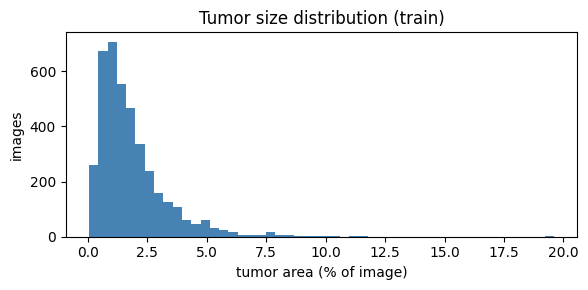

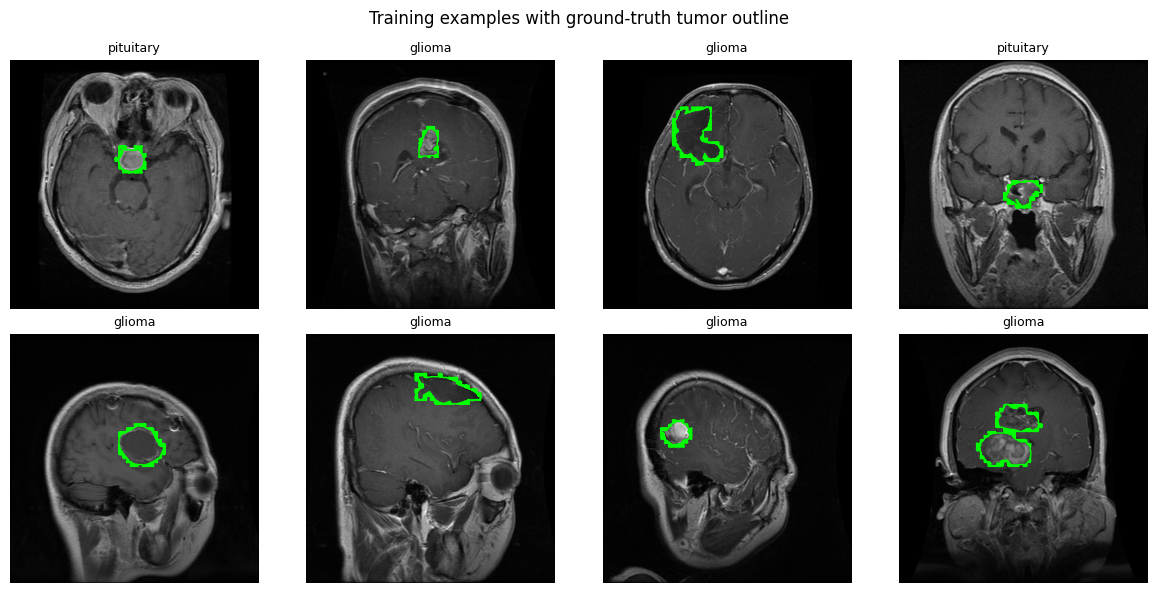

In [ ]:
mask_values, area_fraction, size_mismatch = set(), [], 0
for image_path, mask_path in tqdm(train_items, leave=False):
    with Image.open(mask_path) as m, Image.open(image_path) as im:
        size_mismatch += int(im.size != m.size)
        arr = np.asarray(m.convert("L"))
    mask_values.update(np.unique(arr).tolist()[:10])
    area_fraction.append(float((arr > 0).mean()))
area_fraction = np.array(area_fraction)

print("Mask pixel values:", sorted(mask_values)[:10])
print(f"Image/mask size mismatches: {size_mismatch}")
print(f"Empty masks: {(area_fraction == 0).sum()} of {len(area_fraction)}")
print(f"Tumor area as share of the image: median {np.median(area_fraction):.1%} | "
      f"5th-95th percentile {np.percentile(area_fraction, 5):.1%} - {np.percentile(area_fraction, 95):.1%}")

meta_df = pd.DataFrame([{"tumor": name_parts(p)[0], "plane": PLANE_NAMES.get(name_parts(p)[1], name_parts(p)[1])}
                        for p, _ in train_items])
print("\nTrain images by tumor type and plane:")
display(pd.crosstab(meta_df["tumor"], meta_df["plane"]))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(area_fraction * 100, bins=50, color="steelblue")
ax.set_xlabel("tumor area (% of image)")
ax.set_ylabel("images")
ax.set_title("Tumor size distribution (train)")
plt.tight_layout()
plt.show()

rng = random.Random(SEED)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (image_path, mask_path) in zip(axes.flat, rng.sample(train_items, 8)):
    image = np.asarray(Image.open(image_path).convert("L"))
    mask = np.asarray(Image.open(mask_path).convert("L")) > 0
    ax.imshow(image, cmap="gray")
    if mask.any():
        ax.contour(mask, levels=[0.5], colors="lime", linewidths=1)
    ax.set_title(name_parts(image_path)[0], fontsize=9)
    ax.axis("off")
plt.suptitle("Training examples with ground-truth tumor outline")
plt.tight_layout()
plt.show()

## 3. Duplicate images between train and test

While exploring the data we noticed that some test images look identical to training images. A model can score well on such images just by remembering them, so we measure how many there are and remove them.

**Similarity measure.** Each image is padded to a square, resized to 32×32 and flattened to a vector. For two images $x, y$ with $n$ pixels, the Pearson correlation is

$$r(x,y)=\frac{1}{n}\sum_{i=1}^{n}\frac{(x_i-\bar{x})(y_i-\bar{y})}{\sigma_x\,\sigma_y}$$

$r = 1$ means identical up to brightness/contrast. We also compare against the mirrored image and keep the larger value.

**Why this is not chance.**
1. Two unrelated images have a low $r$ (see the random-pair numbers below).
2. Yet a large share of test images have a training image with $r > 0.95$.
3. Their tumor masks also coincide: the Dice overlap of the two masks (formula in section 5) is close to 1 for matched pairs and close to 0 for random pairs. A coincidence would not reproduce the tumor outline.

Random pairs of train images : median r = 0.56 | share with r > 0.95: 0.02%
Test images with a train image at r > 0.95: 730 of 860 (84.9%); with r > 0.99: 570
Mask Dice of matched pairs: median 0.87 | of random pairs: median 0.00


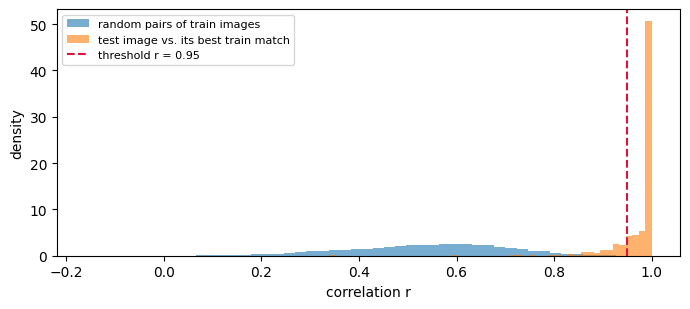

In [ ]:
FP_SIZE = 32
DUP_THRESH = 0.95
RESAMPLE = getattr(Image, "Resampling", Image)

def pad_to_square(image, fill=0):
    """Grayscale + zero-pad to a square canvas (keeps the aspect ratio when resizing)."""
    image = image.convert("L")
    width, height = image.size
    if width == height:
        return image
    side = max(width, height)
    canvas = Image.new("L", (side, side), fill)
    canvas.paste(image, ((side - width) // 2, (side - height) // 2))
    return canvas


def load_square(path):
    with Image.open(path) as im:
        return pad_to_square(im)


def fingerprint(path):
    small = load_square(path).resize((FP_SIZE, FP_SIZE), RESAMPLE.BILINEAR)
    v = np.asarray(small, dtype=np.float32).ravel()
    v = (v - v.mean()) / (v.std() + 1e-6)
    return v / np.sqrt(v.size)              # dot product of two fingerprints = Pearson r


def fingerprints(items):
    with ThreadPoolExecutor(max_workers=8) as pool:
        return np.stack(list(tqdm(pool.map(lambda item: fingerprint(item[0]), items),
                                  total=len(items), leave=False)))


def similarity(a, b):
    """r between every row of a and every row of b; best of 'as is' and 'a mirrored'."""
    a_mirrored = np.ascontiguousarray(a.reshape(-1, FP_SIZE, FP_SIZE)[:, :, ::-1]).reshape(len(a), -1)
    return np.maximum(a @ b.T, a_mirrored @ b.T)


def small_mask(mask_path, size=64):
    return np.asarray(load_square(mask_path).resize((size, size), RESAMPLE.NEAREST)) > 0


def mask_dice(a, b):
    """Dice overlap of two masks, best of 'as is' and 'b mirrored'."""
    best = 0.0
    for other in (b, b[:, ::-1]):
        denom = a.sum() + other.sum()
        best = max(best, 1.0 if denom == 0 else 2 * np.logical_and(a, other).sum() / denom)
    return best


fp_train, fp_test = fingerprints(train_items), fingerprints(test_items)
S = similarity(fp_test, fp_train)           # (n_test, n_train)
best_idx, best_r = S.argmax(axis=1), S.max(axis=1)
rng_np = np.random.default_rng(SEED)

# 1) unrelated images: random pairs of training images
pairs = rng_np.integers(0, len(train_items), size=(20000, 2))
pairs = pairs[pairs[:, 0] != pairs[:, 1]]
r_random = np.einsum("ij,ij->i", fp_train[pairs[:, 0]], fp_train[pairs[:, 1]])
print(f"Random pairs of train images : median r = {np.median(r_random):.2f} | "
      f"share with r > {DUP_THRESH}: {(r_random > DUP_THRESH).mean():.2%}")

# 2) test images that have a near-copy in train
has_match = best_r > DUP_THRESH
print(f"Test images with a train image at r > {DUP_THRESH}: {has_match.sum()} of {len(test_items)} "
      f"({has_match.mean():.1%}); with r > 0.99: {(best_r > 0.99).sum()}")

# 3) do the tumor masks of matched pairs coincide? (300 matched vs 300 random test/train pairs)
matched = rng_np.choice(np.where(has_match)[0], size=min(300, int(has_match.sum())), replace=False)
dice_matched = [mask_dice(small_mask(test_items[i][1]), small_mask(train_items[best_idx[i]][1])) for i in matched]
rand_pairs = zip(rng_np.integers(0, len(test_items), 300), rng_np.integers(0, len(train_items), 300))
dice_random = [mask_dice(small_mask(test_items[i][1]), small_mask(train_items[j][1])) for i, j in rand_pairs]
print(f"Mask Dice of matched pairs: median {np.median(dice_matched):.2f} | of random pairs: median {np.median(dice_random):.2f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(r_random, bins=50, density=True, alpha=0.6, label="random pairs of train images")
ax.hist(best_r, bins=50, density=True, alpha=0.6, label="test image vs. its best train match")
ax.axvline(DUP_THRESH, color="crimson", linestyle="--", label=f"threshold r = {DUP_THRESH}")
ax.set_xlabel("correlation r"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

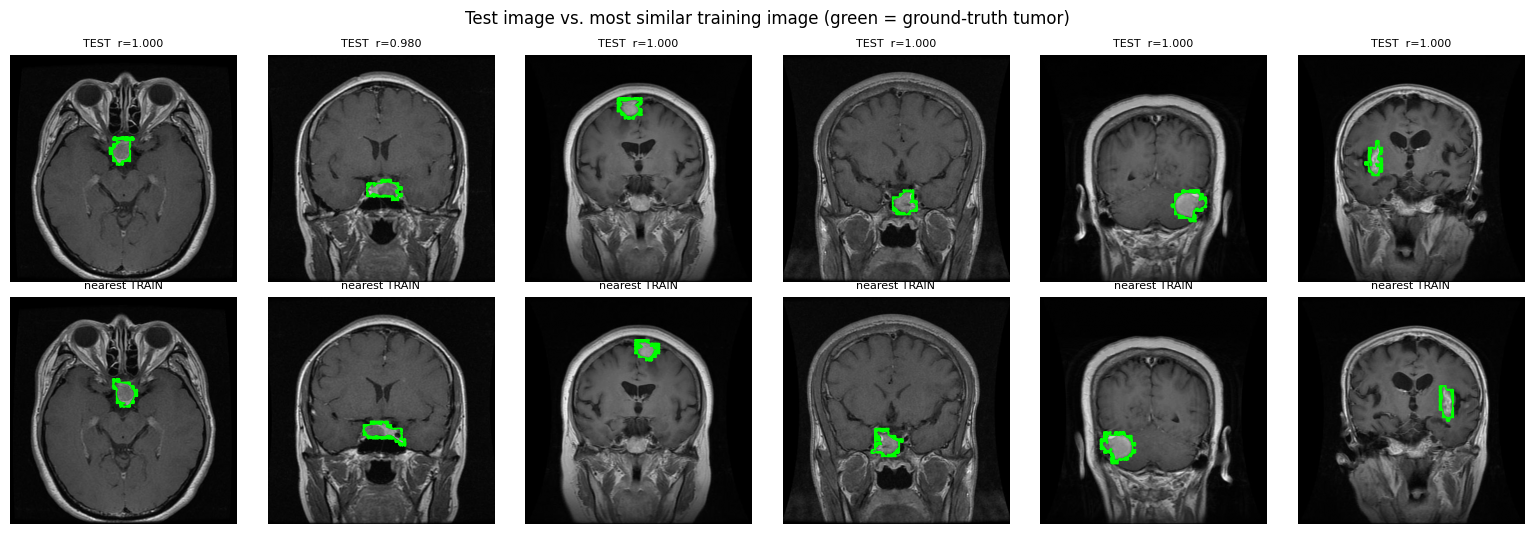

In [ ]:
# Random test images with r > 0.98 (top) and their most similar training image (bottom), with masks.
candidates = np.where(best_r > 0.98)[0]
pick = np.random.default_rng(SEED).choice(candidates, size=min(6, len(candidates)), replace=False)
fig, axes = plt.subplots(2, len(pick), figsize=(2.6 * len(pick), 5.4), squeeze=False)
for col, i in enumerate(pick):
    for row, ((image_path, mask_path), title) in enumerate([(test_items[i], f"TEST  r={best_r[i]:.3f}"),
                                                           (train_items[best_idx[i]], "nearest TRAIN")]):
        axes[row, col].imshow(load_square(image_path), cmap="gray")
        mask = np.asarray(load_square(mask_path)) > 0
        if mask.any():
            axes[row, col].contour(mask, levels=[0.5], colors="lime", linewidths=1)
        axes[row, col].set_title(title, fontsize=8)
        axes[row, col].axis("off")
plt.suptitle("Test image vs. most similar training image (green = ground-truth tumor)")
plt.tight_layout()
plt.show()

### Removing the duplicates

Every training image with $r > 0.95$ to **any** test image is removed. The official test set is left untouched. Near-copies *inside* the training set are put in the same group, so they end up together in either train or validation (section 4). This is a practical cleaning step, not a guarantee of patient-level independence.

In [ ]:
is_copy_of_test = (S > DUP_THRESH).any(axis=0)
print(f"Removed from train: {int(is_copy_of_test.sum())} of {len(train_items)} images "
      f"({100 * is_copy_of_test.mean():.0f}%)")

train_items = [item for item, d in zip(train_items, is_copy_of_test) if not d]
fp_train = fp_train[~is_copy_of_test]
print(f"Remaining train images: {len(train_items)} | official test images: {len(test_items)}")

# Group near-copies inside the remaining train set (used for the validation split).
S_train = similarity(fp_train, fp_train)
np.fill_diagonal(S_train, 0)
_, train_group_ids = connected_components(csr_matrix(S_train > DUP_THRESH), directed=False)
del S_train

Removed from train: 1679 of 3933 images (43%)
Remaining train images: 2254 | official test images: 860


## 4. Preprocessing and data loaders

Image and mask are padded to a square, resized to `256 x 256` (bilinear for the image, nearest-neighbour for the mask), and the image is standardized with a per-image z-score. Training-only augmentation is applied to image and mask together: a small random rotation and zoom, plus a left-right flip that is skipped for sagittal slices (mirroring a sagittal view swaps front and back).

A stratified validation subset (about 14%) is drawn **only from the cleaned training split**, stratified by tumor type. Near-copies found above stay together, so validation images are not near-copies of training images. Both models use this same train/validation split.

Train: 1,930 | validation: 324 | official test: 860
Validation tumor types: {'glioma': 112, 'meningioma': 128, 'pituitary': 84}
Batch: (16, 1, 256, 256) (16, 1, 256, 256) | mask values: [0.0, 1.0]
Image mean -0.000 | std 1.000


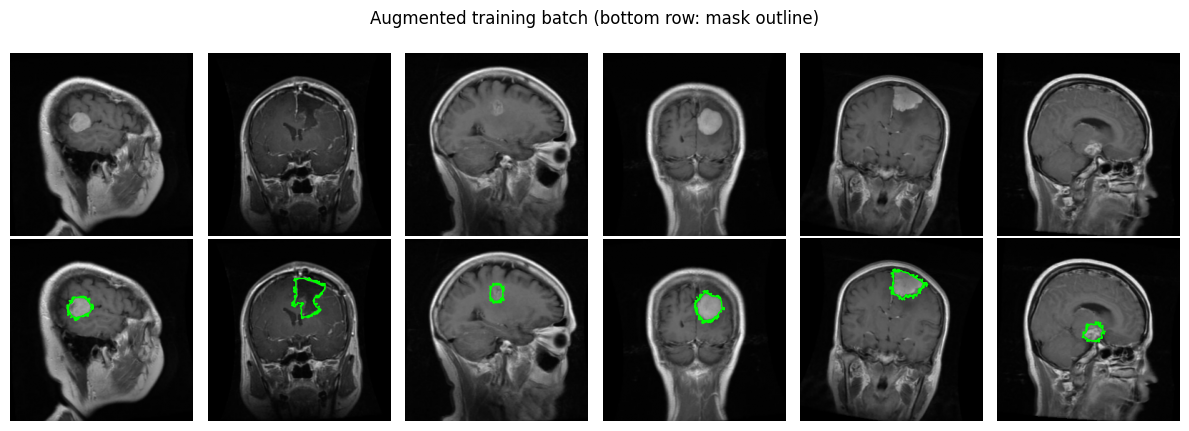

In [ ]:
def zscore(tensor):
    return (tensor - tensor.mean()) / (tensor.std(unbiased=False) + 1e-6)


class SegDataset(Dataset):
    def __init__(self, items, train=False):
        self.items = items
        self.train = train

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        image_path, mask_path = self.items[index]
        image = load_square(image_path).resize((IMG_SIZE, IMG_SIZE), RESAMPLE.BILINEAR)
        mask = load_square(mask_path).resize((IMG_SIZE, IMG_SIZE), RESAMPLE.NEAREST)
        if self.train:
            if name_parts(image_path)[1] != "sa" and torch.rand(1).item() < 0.5:
                image, mask = TF.hflip(image), TF.hflip(mask)
            angle = (torch.rand(1).item() * 2 - 1) * 10
            scale = 1 + (torch.rand(1).item() * 2 - 1) * 0.05
            kwargs = dict(angle=angle, translate=[0, 0], scale=scale, shear=[0.0, 0.0])
            image = TF.affine(image, interpolation=InterpolationMode.BILINEAR, **kwargs)
            mask = TF.affine(mask, interpolation=InterpolationMode.NEAREST, **kwargs)
        x = zscore(TF.to_tensor(image))
        y = (TF.pil_to_tensor(mask) > 0).float()
        return x, y


# Group-aware split, stratified by tumor type: about 1/7 of the cleaned train set becomes validation.
tumor_types = [name_parts(p)[0] for p, _ in train_items]
tumor_codes = np.array([sorted(set(tumor_types)).index(t) for t in tumor_types])
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(np.zeros(len(train_items)), tumor_codes, groups=train_group_ids))
train_split = [train_items[i] for i in train_idx]
val_split = [train_items[i] for i in val_idx]

train_ds = SegDataset(train_split, train=True)
val_ds = SegDataset(val_split)
test_ds = SegDataset(test_items)

train_generator = torch.Generator().manual_seed(SEED)
loader_common = {"num_workers": NUM_WORKERS, "pin_memory": torch.cuda.is_available(), "worker_init_fn": seed_worker}
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator, **loader_common)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, **loader_common)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, **loader_common)

print(f"Train: {len(train_ds):,} | validation: {len(val_ds):,} | official test: {len(test_ds):,}")
print("Validation tumor types:", dict(Counter(name_parts(p)[0] for p, _ in val_split)))

# Sanity check: shapes, value ranges and a few augmented examples.
xb, yb = next(iter(train_loader))
print("Batch:", tuple(xb.shape), tuple(yb.shape), "| mask values:", yb.unique().tolist())
print(f"Image mean {xb.mean().item():.3f} | std {xb.std().item():.3f}")

fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for k in range(6):
    axes[0, k].imshow(xb[k, 0], cmap="gray"); axes[0, k].axis("off")
    axes[1, k].imshow(xb[k, 0], cmap="gray")
    if yb[k, 0].any():
        axes[1, k].contour(yb[k, 0].numpy(), levels=[0.5], colors="lime", linewidths=1)
    axes[1, k].axis("off")
plt.suptitle("Augmented training batch (bottom row: mask outline)")
plt.tight_layout()
plt.show()

## 5. Metrics

For a predicted mask $P$ and a ground-truth mask $G$ (sets of tumor pixels):

$$\mathrm{Dice}=\frac{2\,|P\cap G|}{|P|+|G|},\qquad \mathrm{IoU}=\frac{|P\cap G|}{|P\cup G|}$$

Both are computed **per image** and averaged. An image with an empty prediction and a non-empty mask scores 0. All models are evaluated on the same `256 x 256` padded frame, so their numbers are directly comparable.

In [ ]:
def dice_iou(pred, gt, eps=1e-7):
    """Per-image Dice and IoU for boolean tensors of shape (N, H, W)."""
    pred, gt = pred.flatten(1).float(), gt.flatten(1).float()
    inter = (pred * gt).sum(1)
    p, g = pred.sum(1), gt.sum(1)
    return (2 * inter + eps) / (p + g + eps), (inter + eps) / (p + g - inter + eps)


def collect_loader(loader):
    images, masks = [], []
    for x, y in loader:
        images.append(x[:, 0]); masks.append(y[:, 0].bool())
    return torch.cat(images), torch.cat(masks)


test_images, test_gt = collect_loader(test_loader)    # (N, H, W) tensors, same order as test_items
test_tumor = np.array([name_parts(p)[0] for p, _ in test_items])
test_plane = np.array([PLANE_NAMES.get(name_parts(p)[1], name_parts(p)[1]) for p, _ in test_items])
test_results = {}


def report(name, pred):
    """Store and print test metrics for a (N, H, W) boolean prediction tensor."""
    dice, iou = dice_iou(pred, test_gt)
    dice, iou = dice.numpy(), iou.numpy()
    test_results[name] = {"dice": dice, "iou": iou, "pred": pred}
    print(f"{name}: mean Dice {dice.mean():.4f} | mean IoU {iou.mean():.4f} | "
          f"median Dice {np.median(dice):.4f} | images with Dice < 0.5: {(dice < 0.5).mean():.1%}")
    by_group = pd.DataFrame({"tumor": test_tumor, "plane": test_plane, "dice": dice})
    print("\nMean Dice by tumor type:");  display(by_group.groupby("tumor")["dice"].agg(["mean", "count"]).round(3))
    print("Mean Dice by plane:");        display(by_group.groupby("plane")["dice"].agg(["mean", "count"]).round(3))

## 6. Model 1 — U-Net baseline

A compact U-Net (about 2M parameters) trained from scratch: four down-sampling stages, transposed-convolution up-sampling and skip connections. The loss is binary cross-entropy plus soft Dice loss, which copes with the small tumor area. The checkpoint with the highest **validation Dice** is kept; early stopping and learning-rate scheduling use validation data only.

Transposed convolutions are used for up-sampling because bilinear interpolation has no deterministic CUDA backward pass.

Trainable parameters: 1,942,289
Initial weight checksum: 1444.834397
Epoch 01/40 |   27s | train loss 1.357 | val loss 1.190, Dice 0.410, IoU 0.289  <- best validation Dice
Epoch 02/40 |   26s | train loss 1.048 | val loss 1.019, Dice 0.343, IoU 0.225
Epoch 03/40 |   26s | train loss 0.806 | val loss 0.649, Dice 0.629, IoU 0.524  <- best validation Dice
Epoch 04/40 |   27s | train loss 0.601 | val loss 0.518, Dice 0.607, IoU 0.491
Epoch 05/40 |   27s | train loss 0.476 | val loss 0.435, Dice 0.650, IoU 0.553  <- best validation Dice
Epoch 06/40 |   28s | train loss 0.434 | val loss 0.363, Dice 0.705, IoU 0.603  <- best validation Dice
Epoch 07/40 |   28s | train loss 0.393 | val loss 0.391, Dice 0.677, IoU 0.560
Epoch 08/40 |   27s | train loss 0.364 | val loss 0.351, Dice 0.704, IoU 0.605
Epoch 09/40 |   27s | train loss 0.359 | val loss 0.323, Dice 0.729, IoU 0.633  <- best validation Dice
Epoch 10/40 |   28s | train loss 0.333 | val loss 0.337, Dice 0.722, IoU 0.615
Epoch 11/40 |   

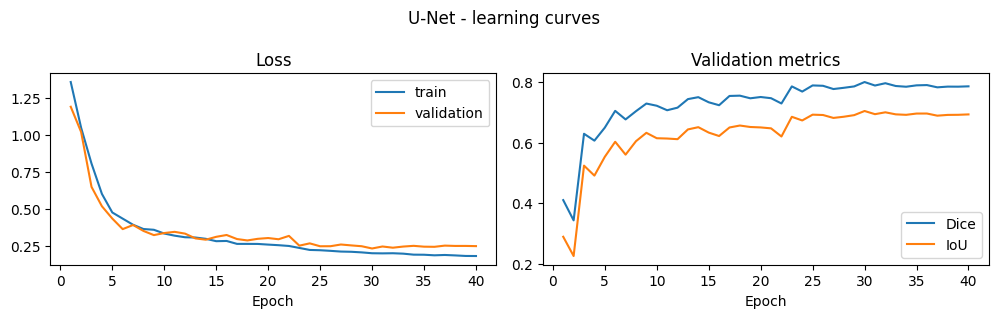

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        chs = [base, base * 2, base * 4, base * 8, base * 16]
        self.encoders = nn.ModuleList([DoubleConv(1, chs[0])] +
                                      [DoubleConv(chs[i], chs[i + 1]) for i in range(4)])
        self.pool = nn.MaxPool2d(2)
        self.ups = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in range(4)])
        self.decoders = nn.ModuleList([DoubleConv(chs[i] * 2, chs[i]) for i in range(4)])
        self.head = nn.Conv2d(chs[0], 1, 1)

    def forward(self, x):
        skips = []
        for i, enc in enumerate(self.encoders):
            x = enc(x if i == 0 else self.pool(x))
            skips.append(x)
        x = skips[-1]
        for i in reversed(range(4)):
            x = self.decoders[i](torch.cat([self.ups[i](x), skips[i]], dim=1))
        return self.head(x)


def weight_checksum(model):
    """Single number that identifies the model's weights; equal checksums = equal initial weights."""
    return sum(p.detach().double().sum().item() for p in model.parameters())


bce = nn.BCEWithLogitsLoss()


def seg_loss(logits, masks):
    probs, m = torch.sigmoid(logits).flatten(1), masks.flatten(1)
    dice_term = 1 - (2 * (probs * m).sum(1) + 1) / (probs.sum(1) + m.sum(1) + 1)
    return bce(logits, masks) + dice_term.mean()


@torch.no_grad()
def run_unet(model, loader):
    """Returns mean loss and boolean predictions / ground truth, shape (N, H, W)."""
    model.eval()
    loss_sum, count, preds, gts = 0.0, 0, [], []
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        logits = model(images)
        loss_sum += seg_loss(logits, masks).item() * len(images)
        count += len(images)
        preds.append((logits > 0).cpu()[:, 0])          # logit > 0  <=>  probability > 0.5
        gts.append(masks.bool().cpu()[:, 0])
    return loss_sum / count, torch.cat(preds), torch.cat(gts)


def fit_unet(model, epochs=40, patience=10, lr=1e-3):
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", patience=3, factor=0.5)
    history, best_state, best_dice, bad_epochs = [], None, -1.0, 0
    for epoch in range(1, epochs + 1):
        start = time.time()
        model.train()
        loss_sum, count = 0.0, 0
        for images, masks in train_loader:
            images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = seg_loss(model(images), masks)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(images); count += len(images)
        val_loss, val_pred, val_gt = run_unet(model, val_loader)
        val_dice, val_iou = (m.mean().item() for m in dice_iou(val_pred, val_gt))
        scheduler.step(val_loss)
        history.append({"epoch": epoch, "train_loss": loss_sum / count, "val_loss": val_loss,
                        "val_dice": val_dice, "val_iou": val_iou})
        improved = val_dice > best_dice + 1e-6
        if improved:
            best_dice, best_state, bad_epochs = val_dice, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
        print(f"Epoch {epoch:02d}/{epochs} | {time.time() - start:4.0f}s | train loss {loss_sum / count:.3f} | "
              f"val loss {val_loss:.3f}, Dice {val_dice:.3f}, IoU {val_iou:.3f}"
              f"{'  <- best validation Dice' if improved else ''}")
        if bad_epochs >= patience:
            print(f"Early stopping after {patience} epochs without validation Dice improvement.")
            break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_dice


seed_everything(SEED)                       # same initial weights on every run
unet = UNet().to(device)
print(f"Trainable parameters: {sum(p.numel() for p in unet.parameters() if p.requires_grad):,}")
print(f"Initial weight checksum: {weight_checksum(unet):.6f}")

seed_everything(SEED)                       # same batch order / augmentation on every run
train_loader.generator.manual_seed(SEED)
unet, unet_history, unet_best = fit_unet(unet)
print(f"Best validation Dice: {unet_best:.4f}")
torch.save(unet.state_dict(), CKPT_DIR / "unet_baseline.pt")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(unet_history["epoch"], unet_history["train_loss"], label="train")
axes[0].plot(unet_history["epoch"], unet_history["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(unet_history["epoch"], unet_history["val_dice"], label="Dice")
axes[1].plot(unet_history["epoch"], unet_history["val_iou"], label="IoU")
axes[1].set_title("Validation metrics"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.suptitle("U-Net - learning curves")
plt.tight_layout()
plt.show()

In [ ]:
# Evaluate the U-Net on the official test set.
_, unet_test_pred, _ = run_unet(unet, test_loader)
report("U-Net baseline", unet_test_pred)

U-Net baseline: mean Dice 0.7857 | mean IoU 0.6864 | median Dice 0.8714 | images with Dice < 0.5: 9.9%

Mean Dice by tumor type:


,mean,count
tumor,,
glioma,0.684,254
meningioma,0.852,306
pituitary,0.805,300


Mean Dice by plane:


,mean,count
plane,,
axial,0.756,346
coronal,0.780,257
sagittal,0.831,257


## 7. Model 2 — YOLO segmentation

[Ultralytics](https://docs.ultralytics.com/) YOLO is an instance-segmentation model, so the masks are first converted to polygon labels (one class, `tumor`). We use the small pretrained `yolo11n-seg` checkpoint and fine-tune it on the **same cleaned train/validation split** and the same `256 x 256` padded images as the U-Net. For evaluation the predicted instance masks of an image are merged into a single binary mask and scored with exactly the same Dice/IoU code.

Settings worth knowing: YOLO's built-in left-right flip is turned off (it cannot skip sagittal slices), mixed precision is off and the seed is fixed so the run is repeatable. The best checkpoint is chosen by YOLO's own validation metric.

In [ ]:
YOLO_DIR = Path("yolo_data")
shutil.rmtree(YOLO_DIR, ignore_errors=True)


def export_yolo(items, split):
    """Save padded/resized images and polygon labels (class 0 = tumor) in YOLO format."""
    image_out, label_out = YOLO_DIR / "images" / split, YOLO_DIR / "labels" / split
    image_out.mkdir(parents=True, exist_ok=True); label_out.mkdir(parents=True, exist_ok=True)
    for image_path, mask_path in items:
        load_square(image_path).resize((IMG_SIZE, IMG_SIZE), RESAMPLE.BILINEAR).save(image_out / f"{image_path.stem}.png")
        mask = (np.asarray(load_square(mask_path).resize((IMG_SIZE, IMG_SIZE), RESAMPLE.NEAREST)) > 0).astype(np.uint8)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        lines = []
        for contour in contours:
            if len(contour) >= 3 and cv2.contourArea(contour) >= 4:
                points = contour.reshape(-1, 2) / IMG_SIZE
                lines.append("0 " + " ".join(f"{v:.5f}" for v in points.ravel()))
        (label_out / f"{image_path.stem}.txt").write_text("\n".join(lines))


for items, split in [(train_split, "train"), (val_split, "val"), (test_items, "test")]:
    export_yolo(items, split)

(YOLO_DIR / "data.yaml").write_text(
    f"path: {YOLO_DIR.resolve()}\ntrain: images/train\nval: images/val\nnames:\n  0: tumor\n"
)
print({split: len(list((YOLO_DIR / "images" / split).glob("*.png"))) for split in ["train", "val", "test"]})

# Sanity check of the label conversion: rasterize the test polygons again and compare with the true masks.
def rasterize(label_path):
    canvas = np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)
    for line in label_path.read_text().splitlines():
        points = (np.array(line.split()[1:], dtype=np.float64).reshape(-1, 2) * IMG_SIZE).round().astype(np.int32)
        cv2.fillPoly(canvas, [points], 1)
    return canvas > 0


polygon_masks = torch.from_numpy(np.stack([rasterize(YOLO_DIR / "labels" / "test" / f"{p.stem}.txt") for p, _ in test_items]))
polygon_dice, _ = dice_iou(polygon_masks, test_gt)
print(f"Polygon labels vs. true test masks: mean Dice {polygon_dice.mean():.4f}  (ceiling for any polygon-based model)")

{'train': 1930, 'val': 324, 'test': 860}
Polygon labels vs. true test masks: mean Dice 0.9831  (ceiling for any polygon-based model)


In [ ]:
seed_everything(SEED)
try:
    yolo = YOLO("yolo11n-seg.pt")
except Exception:                           # older Ultralytics releases
    yolo = YOLO("yolov8n-seg.pt")

yolo.train(
    data=str(YOLO_DIR / "data.yaml"),
    epochs=40,
    patience=10,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    seed=SEED,
    deterministic=True,
    amp=False,
    workers=NUM_WORKERS,
    fliplr=0.0,
    plots=False,
    project=str(Path("runs").resolve()),
    name="yolo_seg",
    exist_ok=True,
)
yolo_best_path = Path(yolo.trainer.save_dir) / "weights" / "best.pt"
shutil.copy(yolo_best_path, CKPT_DIR / "yolo_seg_best.pt")
print("Best weights:", yolo_best_path)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_seg, nbs=64, nms=None, opset=None, optimize=False, optimizer=

In [ ]:
# Evaluate YOLO on the official test set: merge all predicted instances of an image into one binary mask.
yolo_best = YOLO(str(yolo_best_path))
test_paths = [str(YOLO_DIR / "images" / "test" / f"{p.stem}.png") for p, _ in test_items]
yolo_pred = torch.zeros(len(test_paths), IMG_SIZE, IMG_SIZE, dtype=torch.bool)
no_detection = 0
for start in range(0, len(test_paths), 64):
    for k, result in enumerate(yolo_best.predict(test_paths[start:start + 64], imgsz=IMG_SIZE, conf=0.25, verbose=False)):
        if result.masks is None:
            no_detection += 1
            continue
        masks = result.masks.data
        if masks.shape[-2:] != (IMG_SIZE, IMG_SIZE):
            masks = F.interpolate(masks[None].float(), size=(IMG_SIZE, IMG_SIZE), mode="nearest")[0]
        yolo_pred[start + k] = (masks.sum(0) > 0).cpu()
print(f"Test images without any detection: {no_detection} of {len(test_paths)}")
report("YOLO segmentation", yolo_pred)

Test images without any detection: 28 of 860
YOLO segmentation: mean Dice 0.7877 | mean IoU 0.6878 | median Dice 0.8634 | images with Dice < 0.5: 8.5%

Mean Dice by tumor type:


,mean,count
tumor,,
glioma,0.696,254
meningioma,0.883,306
pituitary,0.768,300


Mean Dice by plane:


,mean,count
plane,,
axial,0.758,346
coronal,0.800,257
sagittal,0.816,257


## 8. Compare models

Both models are scored on the official test set with the same metric code. The qualitative figure shows random test images: the green outline is the ground truth, the red outline is the model prediction.

,mean Dice,mean IoU,median Dice,share of images with Dice < 0.5
model,,,,
U-Net baseline,0.7857,0.6864,0.8714,0.0988
YOLO segmentation,0.7877,0.6878,0.8634,0.0849


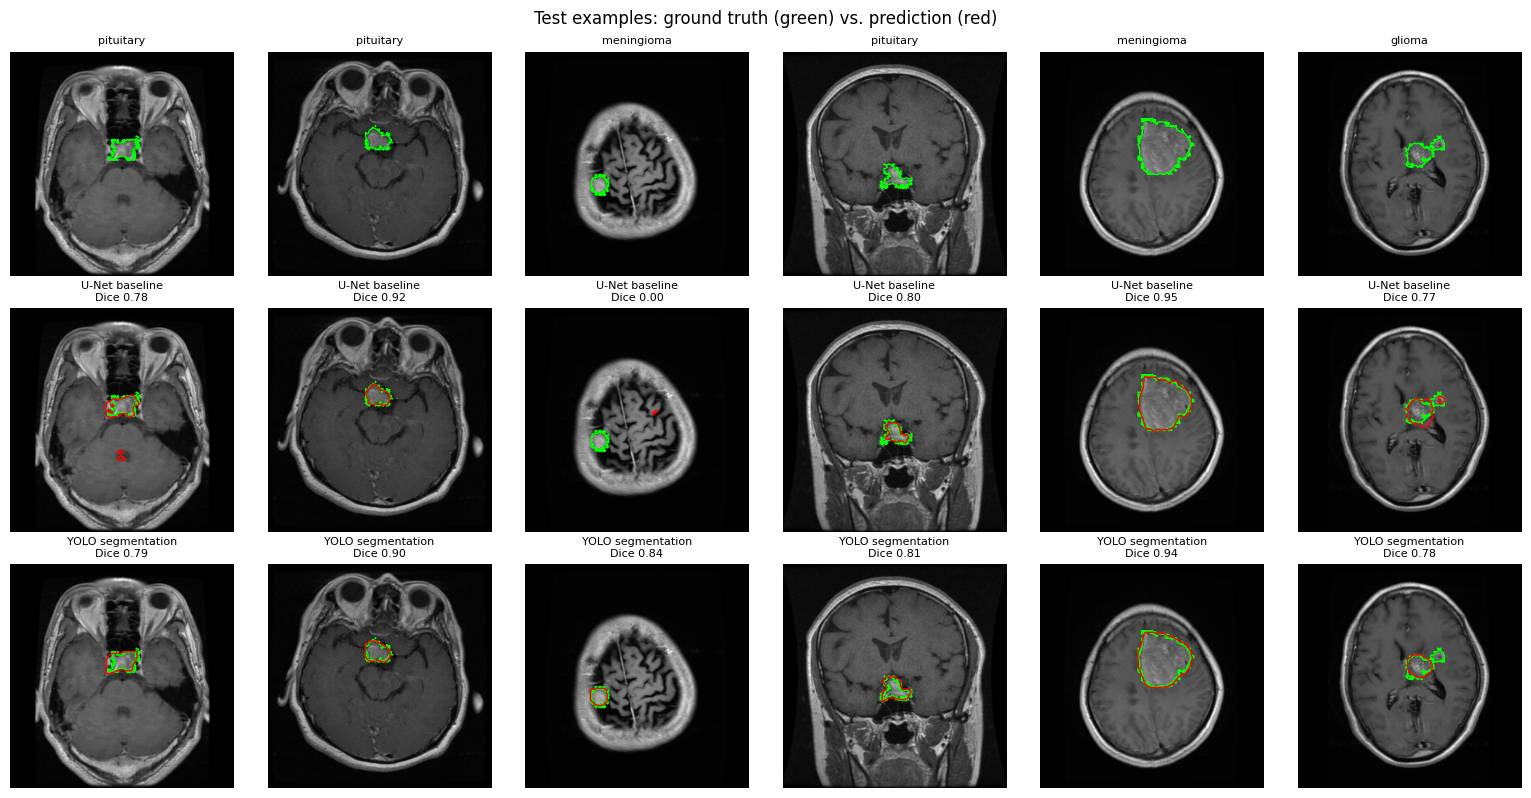

In [ ]:
comparison = pd.DataFrame([
    {"model": name, "mean Dice": r["dice"].mean(), "mean IoU": r["iou"].mean(),
     "median Dice": np.median(r["dice"]), "share of images with Dice < 0.5": (r["dice"] < 0.5).mean()}
    for name, r in test_results.items()
]).set_index("model")
display(comparison.round(4))
comparison.round(4).to_csv("test_results_segmentation.csv")

names = list(test_results)
pick = np.random.default_rng(SEED).choice(len(test_items), size=6, replace=False)
fig, axes = plt.subplots(len(names) + 1, len(pick), figsize=(2.6 * len(pick), 2.7 * (len(names) + 1)))
for col, i in enumerate(pick):
    gt = test_gt[i].numpy()
    axes[0, col].imshow(test_images[i], cmap="gray")
    if gt.any():
        axes[0, col].contour(gt, levels=[0.5], colors="lime", linewidths=1)
    axes[0, col].set_title(f"{test_tumor[i]}", fontsize=8)
    for row, name in enumerate(names, start=1):
        pred = test_results[name]["pred"][i].numpy()
        axes[row, col].imshow(test_images[i], cmap="gray")
        if gt.any():
            axes[row, col].contour(gt, levels=[0.5], colors="lime", linewidths=1)
        if pred.any():
            axes[row, col].contour(pred, levels=[0.5], colors="red", linewidths=1)
        axes[row, col].set_title(f"{name}\nDice {test_results[name]['dice'][i]:.2f}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Test examples: ground truth (green) vs. prediction (red)")
plt.tight_layout()
plt.show()

## 9. Interpretation and limitations

- **Image-level evaluation:** BRISC provides 2D slices, and the public data lack reliable patient identifiers. The dataset paper describes manual efforts to reduce cross-split subject overlap but notes that subject-level independence cannot be guaranteed. Therefore, these scores should not be interpreted as patient-level performance.
- **Duplicates:** many test images had identical or mirrored copies in the training split (section 3). Those training images were removed, so the models cannot score by memorizing them. The check uses a simple 32×32 correlation, so neighbouring slices of the same patient can remain; the test scores are probably still somewhat optimistic.
- **Validation vs. test:** if validation scores are noticeably higher than test scores, neighbouring slices of the same patient probably sit on both sides of the train/validation split. Report the test numbers, not the validation ones.
- **Binary task:** all tumor types are merged into one `tumor` class; no tumor-type classification is done here.
- **Different training recipes:** the U-Net is trained from scratch with a Dice+BCE loss, while YOLO is pretrained, uses its own loss and augmentation (mosaic, scaling, HSV) and predicts polygons. The comparison shows what each recipe achieves with the same data, not which architecture is intrinsically better.
- **Single split and seed:** results are reproducible but come from one split and one training run per model.
- **Clinical use:** this notebook is for educational/research benchmarking only, not for diagnosis or clinical decision-making.

**Reference:** Fateh et al., *BRISC: Annotated Dataset for Brain Tumor Segmentation and Classification*, Scientific Data (2026). [Paper](https://www.nature.com/articles/s41597-026-06753-y) · [Dataset](https://www.kaggle.com/datasets/briscdataset/brisc2025/data)